In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/shai-music-genre-classification/test (2).csv
/kaggle/input/competitions/shai-music-genre-classification/sample_submission (2).csv
/kaggle/input/competitions/shai-music-genre-classification/train (1).csv


In [2]:
import os

for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        if filename.endswith(".csv"):
            print(os.path.join(dirname, filename))

/kaggle/input/competitions/shai-music-genre-classification/test (2).csv
/kaggle/input/competitions/shai-music-genre-classification/sample_submission (2).csv
/kaggle/input/competitions/shai-music-genre-classification/train (1).csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thư mục chứa dữ liệu
data_path = "/kaggle/input/competitions/shai-music-genre-classification/"

# Đọc ba file
train = pd.read_csv(data_path + "train (1).csv")
test = pd.read_csv(data_path + "test (2).csv")
sample_submission = pd.read_csv(data_path + "sample_submission (2).csv")

# Kiểm tra kích thước
print("Train:", train.shape)
print("Test:", test.shape)
print("Submission:", sample_submission.shape)

# Xem 5 dòng đầu tiên
train.head()

Train: (14396, 18)
Test: (3600, 17)
Submission: (3600, 2)


,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,1,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9.0,-6.649,0,0.0381,0.378000,NaN,0.106,0.235,152.429,204947.0,4,9
1,2,The Black Keys,Howlin' for You,67.0,0.725,0.747,11.0,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6
2,3,Royal & the Serpent,phuck u,NaN,0.584,0.804,7.0,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10
3,4,Detroit Blues Band,Missing You,12.0,0.515,0.308,NaN,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,298093.0,3,2
4,5,Coast Contra,My Lady,48.0,0.565,0.777,6.0,-5.096,0,0.2490,0.183000,NaN,0.211,0.619,88.311,254145.0,4,5


In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14396 entries, 0 to 14395
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Id                  14396 non-null  int64  
 1   Artist Name         14396 non-null  object 
 2   Track Name          14396 non-null  object 
 3   Popularity          14063 non-null  float64
 4   danceability        14396 non-null  float64
 5   energy              14396 non-null  float64
 6   key                 12787 non-null  float64
 7   loudness            14396 non-null  float64
 8   mode                14396 non-null  int64  
 9   speechiness         14396 non-null  float64
 10  acousticness        14396 non-null  float64
 11  instrumentalness    10855 non-null  float64
 12  liveness            14396 non-null  float64
 13  valence             14396 non-null  float64
 14  tempo               14396 non-null  float64
 15  duration_in min/ms  14396 non-null  float64
 16  time

#### Thống kê dữ liệu thiếu

In [5]:
missing = pd.DataFrame({
    "So luong thieu": train.isna().sum(),
    "Ty le thieu (%)": train.isna().mean() * 100
})

missing = missing[missing["So luong thieu"] > 0]
missing.sort_values("So luong thieu", ascending=False).round(2)

,So luong thieu,Ty le thieu (%)
instrumentalness,3541,24.60
key,1609,11.18
Popularity,333,2.31


       So luong  Ty le (%)
Class                     
0           500       3.47
1          1098       7.63
2          1018       7.07
3           322       2.24
4           310       2.15
5          1157       8.04
6          2069      14.37
7           461       3.20
8          1483      10.30
9          2019      14.02
10         3959      27.50


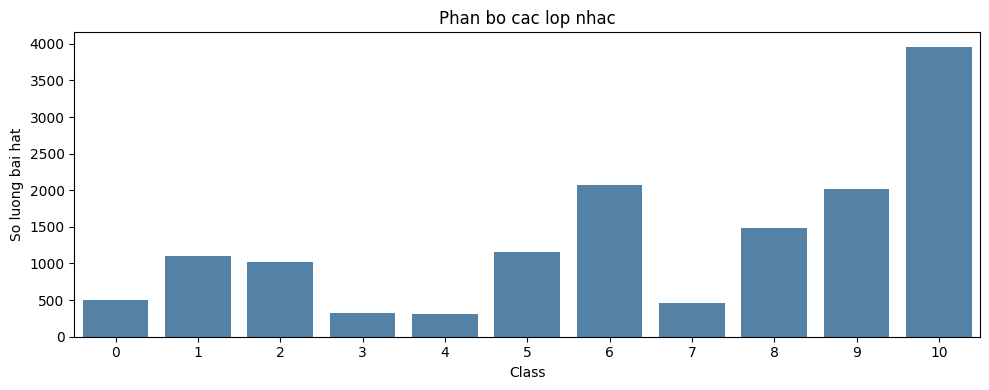

In [6]:
class_summary = pd.DataFrame({
    "So luong": train["Class"].value_counts().sort_index(),
    "Ty le (%)": train["Class"].value_counts(
        normalize=True
    ).sort_index() * 100
})

print(class_summary.round(2))

plt.figure(figsize=(10, 4))
sns.countplot(data=train, x="Class", color="steelblue")
plt.title("Phan bo cac lop nhac")
plt.xlabel("Class")
plt.ylabel("So luong bai hat")
plt.tight_layout()
plt.show()

In [7]:
print("So dong trung hoan toan:", train.duplicated().sum())

print(
    "So dong lap theo nghe si va ten bai:",
    train.duplicated(
        subset=["Artist Name", "Track Name"]
    ).sum()
)

So dong trung hoan toan: 0
So dong lap theo nghe si va ten bai: 1220


In [8]:
print("DU LIEU THIEU:")
print(train.isna().sum()[train.isna().sum() > 0])

print("\nTRUNG TOAN BO DONG:")
print(train.duplicated().sum())

print("\nTRUNG NGHE SI VA TEN BAI:")
print(train.duplicated(subset=["Artist Name", "Track Name"]).sum())

DU LIEU THIEU:
Popularity           333
key                 1609
instrumentalness    3541
dtype: int64

TRUNG TOAN BO DONG:
0

TRUNG NGHE SI VA TEN BAI:
1220


In [9]:
song_cols = ["Artist Name", "Track Name"]

# keep=False: lấy tất cả các dòng thuộc nhóm bài trùng
duplicate_songs = train[
    train.duplicated(subset=song_cols, keep=False)
]

print("Tong so dong thuoc cac nhom trung:", len(duplicate_songs))

duplicate_songs.sort_values(song_cols).head(20)

Tong so dong thuoc cac nhom trung: 2323


,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
382,383,'68,Bad Bite,36.0,0.558,0.977,1.0,-5.082,1,0.2110,0.000618,0.001300,0.3160,0.473,167.984,190031.000000,4,1
6235,6236,'68,Bad Bite,36.0,0.558,0.977,1.0,-5.082,1,0.2110,0.000618,0.001300,0.3160,0.473,167.984,190031.000000,4,6
8214,8215,'68,Bad Bite,36.0,0.558,0.977,1.0,-5.082,1,0.2110,0.000618,0.001300,0.3160,0.473,167.984,190031.000000,4,10
6408,6409,100 gecs,money machine,70.0,0.680,0.659,6.0,-7.186,1,0.1510,0.229000,NaN,0.4740,0.750,98.877,114460.000000,4,9
10871,10872,100 gecs,money machine,70.0,0.680,0.659,6.0,-7.186,1,0.1510,0.229000,NaN,0.4740,0.750,98.877,114460.000000,4,6
6343,6344,1000mods,Mirrors,35.0,0.333,0.820,5.0,-7.361,1,0.0531,0.000288,0.264000,0.0891,0.162,115.120,436333.000000,4,8
8186,8187,1000mods,Mirrors,35.0,0.333,0.820,5.0,-7.361,1,0.0531,0.000288,0.264000,0.0891,0.162,115.120,436333.000000,4,10
7922,7923,13th Floor Elevators,Slip Inside This House - Stereo LP Version,43.0,0.555,0.694,9.0,-8.453,0,0.0426,0.101000,NaN,0.1230,0.602,127.423,482278.000000,4,10
8414,8415,13th Floor Elevators,Slip Inside This House - Stereo LP Version,43.0,0.555,0.694,9.0,-8.453,0,0.0426,0.101000,NaN,0.1230,0.602,127.423,482278.000000,4,2
5810,5811,347aidan,Dancing in My Room,3.0,0.979,0.410,8.0,-11.056,0,0.1120,0.658000,0.000034,0.2050,0.740,119.971,3.002033,4,9


In [10]:
# Đếm số nhãn khác nhau của mỗi bài
labels_per_song = train.groupby(song_cols)["Class"].nunique()

conflicting_songs = labels_per_song[labels_per_song > 1]

print("So nhom bai hat co nhieu nhan:", len(conflicting_songs))
print(conflicting_songs.head(10))

So nhom bai hat co nhieu nhan: 1043
Artist Name           Track Name                                
'68                   Bad Bite                                      3
100 gecs              money machine                                 2
1000mods              Mirrors                                       2
13th Floor Elevators  Slip Inside This House - Stereo LP Version    2
347aidan              Dancing in My Room                            2
4 Non Blondes         What's Up?                                    2
? & The Mysterians    96 Tears                                      2
A Perfect Circle      The Doomed                                    2
AC/DC                 Back In Black                                 2
                      Highway to Hell                               2
Name: Class, dtype: int64


In [11]:
train.drop(columns=["Id", "Class"]).describe().T

,count,mean,std,min,25%,50%,75%,max
Popularity,14063.0,44.525208,17.418940,1.000000,33.000000,44.00000,56.00000,100.000
danceability,14396.0,0.543105,0.165517,0.059600,0.432000,0.54500,0.65800,0.989
energy,14396.0,0.662422,0.235967,0.001210,0.508000,0.69900,0.86100,1.000
key,12787.0,5.953781,3.200013,1.000000,3.000000,6.00000,9.00000,11.000
loudness,14396.0,-7.900852,4.057362,-39.952000,-9.538000,-7.01350,-5.16200,1.342
mode,14396.0,0.640247,0.479944,0.000000,0.000000,1.00000,1.00000,1.000
speechiness,14396.0,0.080181,0.085157,0.022500,0.034800,0.04710,0.08310,0.955
acousticness,14396.0,0.246746,0.310922,0.000000,0.004280,0.08145,0.43225,0.996
instrumentalness,10855.0,0.178129,0.304266,0.000001,0.000088,0.00392,0.20100,0.996
liveness,14396.0,0.195782,0.159258,0.011900,0.097275,0.12900,0.25600,0.992


In [12]:
# Chuẩn hóa tên để nhận diện cùng bài hát
song_info = train[["Artist Name", "Track Name"]].fillna("")

song_info = song_info.apply(
    lambda col: col.str.strip().str.lower()
)

# Mỗi cặp nghệ sĩ + tên bài có một mã nhóm
song_groups = song_info.groupby(
    ["Artist Name", "Track Name"]
).ngroup()

print("So nhom bai hat:", song_groups.nunique())

So nhom bai hat: 13166


In [13]:
from sklearn.model_selection import StratifiedGroupKFold

# V1 dùng các đặc trưng số
X = train.drop(columns=["Id", "Artist Name", "Track Name", "Class"])
y = train["Class"]

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Lấy một fold làm validation
train_idx, valid_idx = next(
    splitter.split(X, y, groups=song_groups)
)

X_train = X.iloc[train_idx].copy()
X_valid = X.iloc[valid_idx].copy()

y_train = y.iloc[train_idx].copy()
y_valid = y.iloc[valid_idx].copy()

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (11536, 14)
X_valid: (2860, 14)
y_train: (11536,)
y_valid: (2860,)


In [14]:
train_groups = set(song_groups.iloc[train_idx])
valid_groups = set(song_groups.iloc[valid_idx])

print("So nhom trung giua hai tap:",
      len(train_groups.intersection(valid_groups)))

class_ratio = pd.DataFrame({
    "Train (%)": y_train.value_counts(normalize=True) * 100,
    "Valid (%)": y_valid.value_counts(normalize=True) * 100
}).sort_index()

print(class_ratio.round(2))

So nhom trung giua hai tap: 0
       Train (%)  Valid (%)
Class                      
0           3.48       3.46
1           7.53       8.01
2           7.02       7.27
3           2.25       2.17
4           2.10       2.38
5           7.97       8.32
6          14.25      14.86
7           3.18       3.29
8          10.38       9.97
9          14.03      14.02
10         27.81      26.26


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

model_v1 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Huấn luyện trên tập train đã chia
model_v1.fit(X_train, y_train)

# Giữ đúng các cột và thứ tự đặc trưng
X_test = test[X_train.columns]

test_predictions = model_v1.predict(X_test)

In [16]:
submission = pd.DataFrame({
    "Id": test["Id"],
    "Class": test_predictions
})

submission.to_csv("/kaggle/working/submission.csv", index=False)

print(submission.shape)
submission.head()

(3600, 2)


,Id,Class
0,14397,6
1,14398,6
2,14399,9
3,14400,10
4,14401,5


In [17]:
from sklearn.metrics import accuracy_score, f1_score

pred_train_v1 = model_v1.predict(X_train)
pred_valid_v1 = model_v1.predict(X_valid)

print("V1 Train Accuracy:",
      accuracy_score(y_train, pred_train_v1))
print("V1 Valid Accuracy:",
      accuracy_score(y_valid, pred_valid_v1))
print("V1 Valid Macro F1:",
      f1_score(y_valid, pred_valid_v1, average="macro"))

V1 Train Accuracy: 0.9218099861303745
V1 Valid Accuracy: 0.5548951048951049
V1 Valid Macro F1: 0.5884906132003637


In [18]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesClassifier

model_v2 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", ExtraTreesClassifier(
        n_estimators=400,
        random_state=42,
        n_jobs=-1
    ))
])

model_v2.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model',
                 ExtraTreesClassifier(n_estimators=400, n_jobs=-1,
                                      random_state=42))])

In [19]:
pred_train_v2 = model_v2.predict(X_train)
pred_valid_v2 = model_v2.predict(X_valid)

comparison = pd.DataFrame({
    "Model": ["V1 - Random Forest", "V2 - Extra Trees"],
    "Train Accuracy": [
        accuracy_score(y_train, pred_train_v1),
        accuracy_score(y_train, pred_train_v2)
    ],
    "Valid Accuracy": [
        accuracy_score(y_valid, pred_valid_v1),
        accuracy_score(y_valid, pred_valid_v2)
    ],
    "Valid Macro F1": [
        f1_score(y_valid, pred_valid_v1, average="macro"),
        f1_score(y_valid, pred_valid_v2, average="macro")
    ]
})

print(comparison.round(4).to_string(index=False))

             Model  Train Accuracy  Valid Accuracy  Valid Macro F1
V1 - Random Forest          0.9218          0.5549          0.5885
  V2 - Extra Trees          0.9218          0.5437          0.5689


In [20]:
print(comparison.round(4).to_string(index=False))

             Model  Train Accuracy  Valid Accuracy  Valid Macro F1
V1 - Random Forest          0.9218          0.5549          0.5885
  V2 - Extra Trees          0.9218          0.5437          0.5689


In [21]:
from sklearn.metrics import classification_report

# Kết quả từng lớp của mô hình tốt nhất hiện tại
print("BAO CAO V1:")
print(classification_report(
    y_valid,
    pred_valid_v1,
    digits=4,
    zero_division=0
))

# Kiểm tra các dòng có cùng đặc trưng số nhưng khác nhãn
feature_cols = X.columns.tolist()

labels_per_features = train.groupby(
    feature_cols,
    dropna=False
)["Class"].nunique()

print(
    "So nhom dac trung giong nhau nhung khac nhan:",
    (labels_per_features > 1).sum()
)

BAO CAO V1:
              precision    recall  f1-score   support

           0     0.7434    0.8485    0.7925        99
           1     0.5000    0.0175    0.0338       229
           2     0.6549    0.3558    0.4611       208
           3     0.8214    0.7419    0.7797        62
           4     0.6769    0.6471    0.6617        68
           5     0.6549    0.7017    0.6775       238
           6     0.4416    0.3200    0.3711       425
           7     0.9778    0.9362    0.9565        94
           8     0.6274    0.5789    0.6022       285
           9     0.5682    0.5711    0.5697       401
          10     0.4637    0.7324    0.5679       751

    accuracy                         0.5549      2860
   macro avg     0.6482    0.5864    0.5885      2860
weighted avg     0.5635    0.5549    0.5283      2860

So nhom dac trung giong nhau nhung khac nhan: 994


In [22]:
from sklearn.base import clone

# Tạo mô hình riêng để huấn luyện trên toàn bộ dữ liệu
# Giữ model_v1 ban đầu để bảo toàn kết quả validation
final_model = clone(model_v1)

X_full = train[X_train.columns]
y_full = train["Class"]

final_model.fit(X_full, y_full)

# Dự đoán tập test
test_predictions = final_model.predict(test[X_train.columns])

# Tạo file đúng định dạng
submission = pd.DataFrame({
    "Id": test["Id"],
    "Class": test_predictions.astype(int)
})

submission.to_csv("/kaggle/working/submission.csv", index=False)

print("Da tao submission.csv")
print("Kich thuoc:", submission.shape)
print(submission.head())

Da tao submission.csv
Kich thuoc: (3600, 2)
      Id  Class
0  14397      6
1  14398      6
2  14399      9
3  14400     10
4  14401      5


In [23]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

model_v3 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

model_v3.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model',
                 RandomForestClassifier(max_depth=15, min_samples_leaf=5,
                                        n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [24]:
from sklearn.metrics import accuracy_score, f1_score

pred_train_v3 = model_v3.predict(X_train)
pred_valid_v3 = model_v3.predict(X_valid)

result_v3 = pd.DataFrame({
    "Model": ["V3 - Random Forest regularized"],
    "Train Accuracy": [
        accuracy_score(y_train, pred_train_v3)
    ],
    "Valid Accuracy": [
        accuracy_score(y_valid, pred_valid_v3)
    ],
    "Valid Macro F1": [
        f1_score(y_valid, pred_valid_v3, average="macro")
    ]
})

comparison_v3 = pd.concat(
    [comparison, result_v3],
    ignore_index=True
)

print(comparison_v3.round(4).to_string(index=False))

                         Model  Train Accuracy  Valid Accuracy  Valid Macro F1
            V1 - Random Forest          0.9218          0.5549          0.5885
              V2 - Extra Trees          0.9218          0.5437          0.5689
V3 - Random Forest regularized          0.7356          0.5462          0.5679


In [25]:
from sklearn.metrics import classification_report

print(classification_report(
    y_valid,
    pred_valid_v3,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

           0     0.7025    0.8586    0.7727        99
           1     0.6667    0.0087    0.0172       229
           2     0.6627    0.2644    0.3780       208
           3     0.7736    0.6613    0.7130        62
           4     0.6780    0.5882    0.6299        68
           5     0.6482    0.6891    0.6680       238
           6     0.4764    0.3318    0.3911       425
           7     0.9778    0.9362    0.9565        94
           8     0.6680    0.5649    0.6122       285
           9     0.5466    0.5411    0.5439       401
          10     0.4494    0.7563    0.5638       751

    accuracy                         0.5462      2860
   macro avg     0.6591    0.5637    0.5679      2860
weighted avg     0.5769    0.5462    0.5165      2860



#### V4

In [26]:
from sklearn.base import clone

# Sao chép cấu hình V1, không thay đổi mô hình V1
model_v4 = clone(model_v1)

# Tăng trọng số cho các lớp ít mẫu
model_v4.set_params(model__class_weight="balanced")

model_v4.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [27]:
pred_train_v4 = model_v4.predict(X_train)
pred_valid_v4 = model_v4.predict(X_valid)

result_v4 = pd.DataFrame({
    "Model": ["V4 - Random Forest balanced"],
    "Train Accuracy": [
        accuracy_score(y_train, pred_train_v4)
    ],
    "Valid Accuracy": [
        accuracy_score(y_valid, pred_valid_v4)
    ],
    "Valid Macro F1": [
        f1_score(y_valid, pred_valid_v4, average="macro")
    ]
})

comparison_v4 = pd.concat(
    [comparison_v3, result_v4],
    ignore_index=True
)

print(comparison_v4.round(4).to_string(index=False))

                         Model  Train Accuracy  Valid Accuracy  Valid Macro F1
            V1 - Random Forest          0.9218          0.5549          0.5885
              V2 - Extra Trees          0.9218          0.5437          0.5689
V3 - Random Forest regularized          0.7356          0.5462          0.5679
   V4 - Random Forest balanced          0.9218          0.5479          0.5796


In [28]:
print(classification_report(
    y_valid,
    pred_valid_v4,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

           0     0.7143    0.8586    0.7798        99
           1     0.2500    0.0131    0.0249       229
           2     0.6094    0.3750    0.4643       208
           3     0.8036    0.7258    0.7627        62
           4     0.6825    0.6324    0.6565        68
           5     0.6332    0.6891    0.6600       238
           6     0.4714    0.3106    0.3745       425
           7     0.9667    0.9255    0.9457        94
           8     0.6299    0.5614    0.5937       285
           9     0.5498    0.5511    0.5504       401
          10     0.4586    0.7310    0.5637       751

    accuracy                         0.5479      2860
   macro avg     0.6154    0.5794    0.5796      2860
weighted avg     0.5375    0.5479    0.5209      2860



#### V5

In [29]:
# Giữ các đặc trưng số cũ và thêm tên nghệ sĩ
numeric_cols = X_train.columns.tolist()
feature_cols_v5 = numeric_cols + ["Artist Name"]

X_train_v5 = train.iloc[train_idx][feature_cols_v5].copy()
X_valid_v5 = train.iloc[valid_idx][feature_cols_v5].copy()

In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor_v5 = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_cols),

    ("artist", Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), ["Artist Name"])
])

model_v5 = Pipeline([
    ("preprocessor", preprocessor_v5),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

model_v5.fit(X_train_v5, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  SimpleImputer(strategy='median'),
                                                  ['Popularity', 'danceability',
                                                   'energy', 'key', 'loudness',
                                                   'mode', 'speechiness',
                                                   'acousticness',
                                                   'instrumentalness',
                                                   'liveness', 'valence',
                                                   'tempo',
                                                   'duration_in min/ms',
                                                   'time_signature']),
                                                 ('artist',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Artist Name'])])),
                ('model',
                 RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [31]:
pred_train_v5 = model_v5.predict(X_train_v5)
pred_valid_v5 = model_v5.predict(X_valid_v5)

comparison_v5 = pd.DataFrame({
    "Model": ["V1 - Numeric", "V5 - Numeric + Artist"],
    "Train Accuracy": [
        accuracy_score(y_train, pred_train_v1),
        accuracy_score(y_train, pred_train_v5)
    ],
    "Valid Accuracy": [
        accuracy_score(y_valid, pred_valid_v1),
        accuracy_score(y_valid, pred_valid_v5)
    ],
    "Valid Macro F1": [
        f1_score(y_valid, pred_valid_v1, average="macro"),
        f1_score(y_valid, pred_valid_v5, average="macro")
    ]
})

print(comparison_v5.round(4).to_string(index=False))

print(classification_report(
    y_valid,
    pred_valid_v5,
    digits=4,
    zero_division=0
))

                Model  Train Accuracy  Valid Accuracy  Valid Macro F1
         V1 - Numeric          0.9218          0.5549          0.5885
V5 - Numeric + Artist          0.9219          0.5685          0.6062
              precision    recall  f1-score   support

           0     0.7857    0.8889    0.8341        99
           1     1.0000    0.0087    0.0173       229
           2     0.7901    0.3077    0.4429       208
           3     0.8679    0.7419    0.8000        62
           4     0.8197    0.7353    0.7752        68
           5     0.6745    0.7227    0.6978       238
           6     0.4771    0.2941    0.3639       425
           7     0.9677    0.9574    0.9626        94
           8     0.6766    0.5579    0.6115       285
           9     0.5893    0.5761    0.5826       401
          10     0.4559    0.7976    0.5801       751

    accuracy                         0.5685      2860
   macro avg     0.7368    0.5989    0.6062      2860
weighted avg     0.6316    0.568

In [32]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

X_numeric = train[numeric_cols]
X_artist = train[feature_cols_v5]
y_all = train["Class"]

cv_results = []

for fold, (tr_idx, va_idx) in enumerate(
    cv.split(X_numeric, y_all, groups=song_groups),
    start=1
):
    models = [
        ("V1", model_v1, X_numeric),
        ("V5", model_v5, X_artist)
    ]

    for name, base_model, features in models:
        model = clone(base_model)

        model.fit(
            features.iloc[tr_idx],
            y_all.iloc[tr_idx]
        )

        predictions = model.predict(features.iloc[va_idx])

        cv_results.append({
            "Fold": fold,
            "Model": name,
            "Accuracy": accuracy_score(
                y_all.iloc[va_idx], predictions
            ),
            "Macro F1": f1_score(
                y_all.iloc[va_idx],
                predictions,
                average="macro"
            )
        })

    print(f"Da xong fold {fold}/5")

cv_results = pd.DataFrame(cv_results)

print("\nKET QUA TUNG FOLD:")
print(cv_results.round(4).to_string(index=False))

print("\nTRUNG BINH VA DO LECH CHUAN:")
print(
    cv_results.groupby("Model")[["Accuracy", "Macro F1"]]
    .agg(["mean", "std"])
    .round(4)
)

Da xong fold 1/5
Da xong fold 2/5
Da xong fold 3/5
Da xong fold 4/5
Da xong fold 5/5

KET QUA TUNG FOLD:
 Fold Model  Accuracy  Macro F1
    1    V1    0.5549    0.5885
    1    V5    0.5685    0.6062
    2    V1    0.5635    0.5846
    2    V5    0.5811    0.5904
    3    V1    0.5346    0.5531
    3    V5    0.5489    0.5523
    4    V1    0.5485    0.5730
    4    V5    0.5673    0.5887
    5    V1    0.5520    0.5840
    5    V5    0.5734    0.5916

TRUNG BINH VA DO LECH CHUAN:
      Accuracy         Macro F1        
          mean     std     mean     std
Model                                  
V1      0.5507  0.0106   0.5766  0.0144
V5      0.5678  0.0119   0.5858  0.0200


In [33]:
from sklearn.base import clone

# Huấn luyện V5 trên toàn bộ dữ liệu có nhãn
final_model_v5 = clone(model_v5)

final_model_v5.fit(
    train[feature_cols_v5],
    train["Class"]
)

# Dự đoán tập test
test_predictions_v5 = final_model_v5.predict(
    test[feature_cols_v5]
)

# Xuất file riêng để phân biệt với submission V1
submission_v5 = pd.DataFrame({
    "Id": test["Id"],
    "Class": test_predictions_v5.astype(int)
})

submission_v5.to_csv(
    "/kaggle/working/submission_v5.csv",
    index=False
)

print("Da tao submission_v5.csv")
print("Kich thuoc:", submission_v5.shape)
print(submission_v5.head())

Da tao submission_v5.csv
Kich thuoc: (3600, 2)
      Id  Class
0  14397      6
1  14398      6
2  14399      9
3  14400     10
4  14401      5


#### v6

In [34]:
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

X_v6 = train[feature_cols_v5].copy()

# CatBoost cần cột phân loại không có giá trị thiếu
X_v6["Artist Name"] = X_v6["Artist Name"].fillna("Unknown")

X_train_v6 = X_v6.iloc[train_idx].copy()
X_valid_v6 = X_v6.iloc[valid_idx].copy()

In [35]:
model_v6 = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    loss_function="MultiClass",
    eval_metric="MultiClass",
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

model_v6.fit(
    X_train_v6,
    y_train,
    cat_features=["Artist Name"],
    eval_set=(X_valid_v6, y_valid),
    early_stopping_rounds=100,
    use_best_model=True
)

0:	learn: 2.3007546	test: 2.3028336	best: 2.3028336 (0)	total: 125ms	remaining: 2m 4s
100:	learn: 1.1064081	test: 1.0668548	best: 1.0668548 (100)	total: 5.18s	remaining: 46.1s
200:	learn: 0.9964801	test: 0.9956838	best: 0.9956838 (200)	total: 10.4s	remaining: 41.4s
300:	learn: 0.9264343	test: 0.9677578	best: 0.9677578 (300)	total: 15.7s	remaining: 36.5s
400:	learn: 0.8774515	test: 0.9565856	best: 0.9565856 (400)	total: 21.1s	remaining: 31.5s
500:	learn: 0.8373932	test: 0.9504689	best: 0.9504689 (500)	total: 26.3s	remaining: 26.2s
600:	learn: 0.7999378	test: 0.9462107	best: 0.9462107 (600)	total: 31.7s	remaining: 21s
700:	learn: 0.7674714	test: 0.9439952	best: 0.9439622 (697)	total: 37s	remaining: 15.8s
800:	learn: 0.7380021	test: 0.9433204	best: 0.9431225 (773)	total: 42.4s	remaining: 10.5s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.9431225434
bestIteration = 773

Shrink model to first 774 iterations.


CatBoostClassifier(allow_writing_files=False, depth=6, eval_metric='MultiClass', iterations=1000, learning_rate=0.05, loss_function='MultiClass', random_seed=42, verbose=100)

In [36]:
pred_train_v6 = model_v6.predict(X_train_v6).ravel().astype(int)
pred_valid_v6 = model_v6.predict(X_valid_v6).ravel().astype(int)

comparison_v6 = pd.DataFrame({
    "Model": ["V5 - Random Forest + Artist", "V6 - CatBoost + Artist"],
    "Train Accuracy": [
        accuracy_score(y_train, pred_train_v5),
        accuracy_score(y_train, pred_train_v6)
    ],
    "Valid Accuracy": [
        accuracy_score(y_valid, pred_valid_v5),
        accuracy_score(y_valid, pred_valid_v6)
    ],
    "Valid Macro F1": [
        f1_score(y_valid, pred_valid_v5, average="macro"),
        f1_score(y_valid, pred_valid_v6, average="macro")
    ]
})

print(comparison_v6.round(4).to_string(index=False))
print("So cay duoc giu:", model_v6.tree_count_)

print(classification_report(
    y_valid,
    pred_valid_v6,
    digits=4,
    zero_division=0
))

                      Model  Train Accuracy  Valid Accuracy  Valid Macro F1
V5 - Random Forest + Artist          0.9219          0.5685          0.6062
     V6 - CatBoost + Artist          0.8224          0.6514          0.6875
So cay duoc giu: 774
              precision    recall  f1-score   support

           0     0.7946    0.8990    0.8436        99
           1     0.1944    0.0306    0.0528       229
           2     0.7385    0.6923    0.7146       208
           3     0.8929    0.8065    0.8475        62
           4     0.8209    0.8088    0.8148        68
           5     0.7566    0.8487    0.8000       238
           6     0.5077    0.4635    0.4846       425
           7     0.9670    0.9362    0.9514        94
           8     0.7177    0.7404    0.7288       285
           9     0.7202    0.6484    0.6824       401
          10     0.5639    0.7457    0.6422       751

    accuracy                         0.6514      2860
   macro avg     0.6977    0.6927    0.6875    

In [37]:
from sklearn.model_selection import StratifiedGroupKFold

cv_v6 = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results_v6 = []

for fold, (tr_idx, va_idx) in enumerate(
    cv_v6.split(X_v6, train["Class"], groups=song_groups),
    start=1
):
    fold_model = CatBoostClassifier(
        iterations=774,
        learning_rate=0.05,
        depth=6,
        loss_function="MultiClass",
        random_seed=42,
        verbose=False,
        allow_writing_files=False
    )

    fold_model.fit(
        X_v6.iloc[tr_idx],
        train["Class"].iloc[tr_idx],
        cat_features=["Artist Name"]
    )

    predictions = (
        fold_model.predict(X_v6.iloc[va_idx])
        .ravel()
        .astype(int)
    )

    results_v6.append({
        "Fold": fold,
        "Accuracy": accuracy_score(
            train["Class"].iloc[va_idx], predictions
        ),
        "Macro F1": f1_score(
            train["Class"].iloc[va_idx],
            predictions,
            average="macro"
        )
    })

    print(f"Da xong fold {fold}/5")

results_v6 = pd.DataFrame(results_v6)

print("\nKET QUA TUNG FOLD:")
print(results_v6.round(4).to_string(index=False))

print("\nTRUNG BINH VA DO LECH CHUAN:")
print(results_v6[["Accuracy", "Macro F1"]].agg(["mean", "std"]).round(4))

Da xong fold 1/5
Da xong fold 2/5
Da xong fold 3/5
Da xong fold 4/5
Da xong fold 5/5

KET QUA TUNG FOLD:
 Fold  Accuracy  Macro F1
    1    0.6514    0.6875
    2    0.6556    0.6865
    3    0.6421    0.6627
    4    0.6475    0.6835
    5    0.6548    0.6985

TRUNG BINH VA DO LECH CHUAN:
      Accuracy  Macro F1
mean    0.6503    0.6837
std     0.0056    0.0131


In [38]:
# Huấn luyện bản cuối trên toàn bộ dữ liệu có nhãn
final_model_v6 = CatBoostClassifier(
    iterations=774,
    learning_rate=0.05,
    depth=6,
    loss_function="MultiClass",
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

final_model_v6.fit(
    X_v6,
    train["Class"],
    cat_features=["Artist Name"]
)

# Chuẩn bị test giống lúc huấn luyện
X_test_v6 = test[feature_cols_v5].copy()
X_test_v6["Artist Name"] = (
    X_test_v6["Artist Name"].fillna("Unknown")
)

# Dự đoán nhãn
test_predictions_v6 = (
    final_model_v6.predict(X_test_v6)
    .ravel()
    .astype(int)
)

# Tạo file nộp bài
submission_v6 = pd.DataFrame({
    "Id": test["Id"],
    "Class": test_predictions_v6
})

submission_v6.to_csv(
    "/kaggle/working/submission_v6.csv",
    index=False
)

print("Da tao submission_v6.csv")
print("Kich thuoc:", submission_v6.shape)
print(submission_v6.head())

0:	learn: 2.3005192	total: 64.8ms	remaining: 50.1s
100:	learn: 1.0909468	total: 5.99s	remaining: 39.9s
200:	learn: 0.9839410	total: 12.1s	remaining: 34.4s
300:	learn: 0.9200190	total: 18.4s	remaining: 28.9s
400:	learn: 0.8756657	total: 24.6s	remaining: 22.9s
500:	learn: 0.8366103	total: 30.8s	remaining: 16.8s
600:	learn: 0.8041458	total: 37.1s	remaining: 10.7s
700:	learn: 0.7744531	total: 43.3s	remaining: 4.51s
773:	learn: 0.7548610	total: 47.9s	remaining: 0us
Da tao submission_v6.csv
Kich thuoc: (3600, 2)
      Id  Class
0  14397      6
1  14398      6
2  14399      9
3  14400     10
4  14401      5
